# E2 · Exploración y calidad de datos

**Fuente:** `data/data.csv`, UCI 697. **Problema:** clasificación Dropout / Enrolled / Graduate al cierre del primer semestre.

**Lectura de `docs/resumen_eda.json`:** 4 424 filas; sin nulos, duplicados exactos ni valores fuera del rango de las ocho variables. Hay 180 estudiantes con cero unidades inscritas, 538 casos con promedio cero y unidades inscritas y 6 perfiles conflictivos al usar solo ocho predictores. No se imputan o eliminan automáticamente sin evidencia.

**Desbalance:** Enrolled es la clase minoritaria (17,95 %), por lo que se prioriza macro-F1 frente a accuracy. Las variables del segundo semestre se excluyen por fuga temporal.


In [8]:
import sys, json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src.datos import (cargar_datos, limpiar, eliminar_duplicados, particionar, verificar_sin_fuga,
                       resumen_particion, separar_xy, resumen_eda, COLUMNA_OBJETIVO, CLASES)

FIG = RAIZ / "docs" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

df = limpiar(cargar_datos())
res = resumen_eda(df)
with open(RAIZ / "docs" / "resumen_eda.json", "w", encoding="utf-8") as f:
    json.dump(res, f, indent=2, ensure_ascii=False)
print("Filas:", res["filas"], "| Columnas:", res["columnas"])

Filas: 4424 | Columnas: 37


In [9]:
simples = {k: v for k, v in res.items()
           if k in ["filas", "columnas", "duplicados_exactos", "perfiles_con_etiqueta_conflictiva",
                    "perfiles_conflictivos_8_variables", "aprobadas_mayor_que_inscritas_s1",
                    "sin_unidades_inscritas_s1", "promedio_cero_con_unidades_s1",
                    "accuracy_si_siempre_clase_mayoritaria"]}
display(pd.Series(simples, name="valor").to_frame())
print("Nulos por columna:", res["nulos_por_columna"] or "ninguno")
print("Fuera de rango (dominio):", {k: v for k, v in res["fuera_de_rango_dominio"].items() if v} or "ninguno")
print("Clases entre estudiantes con 0 unidades en S1:", res["clases_sin_unidades_s1"])
display(pd.DataFrame({"conteo": res["clases"], "proporcion": res["proporcion_clases"]}))

,valor
filas,4424.0000
columnas,37.0000
duplicados_exactos,0.0000
perfiles_con_etiqueta_conflictiva,0.0000
accuracy_si_siempre_clase_mayoritaria,0.4993
aprobadas_mayor_que_inscritas_s1,0.0000
sin_unidades_inscritas_s1,180.0000
promedio_cero_con_unidades_s1,538.0000
perfiles_conflictivos_8_variables,6.0000


Nulos por columna: ninguno
Fuera de rango (dominio): ninguno
Clases entre estudiantes con 0 unidades en S1: {'Dropout': 77, 'Graduate': 75, 'Enrolled': 28}


,conteo,proporcion
Graduate,2209,0.4993
Dropout,1421,0.3212
Enrolled,794,0.1795


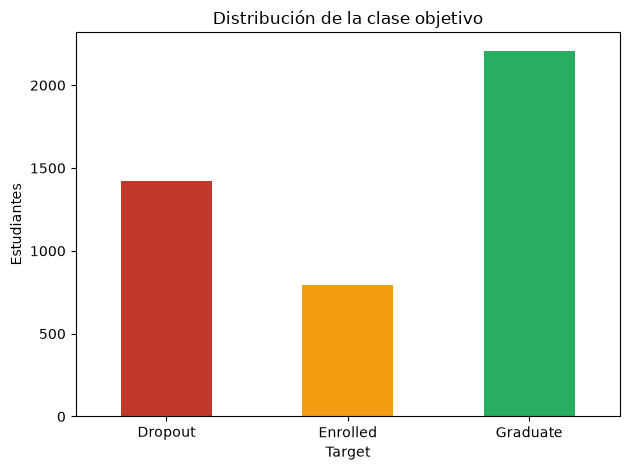

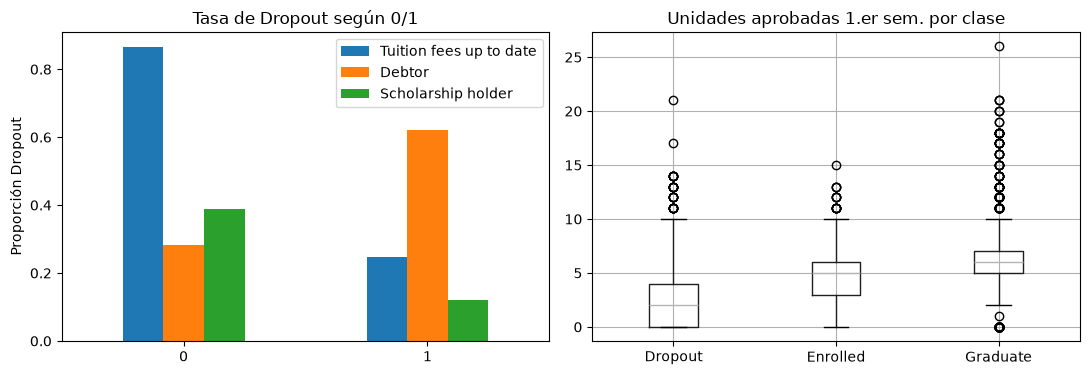

In [10]:
# Figura 01: objetivo
ax = df[COLUMNA_OBJETIVO].value_counts().reindex(CLASES).plot.bar(color=["#c0392b", "#f39c12", "#27ae60"])
ax.set_title("Distribución de la clase objetivo"); ax.set_ylabel("Estudiantes"); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(FIG / "01_objetivo.png", dpi=150); plt.show()

# Figura 02: tasa de Dropout por variable binaria y distribución de unidades aprobadas por clase
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
pd.DataFrame(res["tasa_dropout_por_variable"]).plot.bar(ax=axes[0])
axes[0].set_title("Tasa de Dropout según 0/1"); axes[0].set_ylabel("Proporción Dropout"); axes[0].tick_params(axis="x", rotation=0)
df.boxplot(column="Curricular units 1st sem (approved)", by=COLUMNA_OBJETIVO, ax=axes[1])
axes[1].set_title("Unidades aprobadas 1.er sem. por clase"); axes[1].set_xlabel(""); fig.suptitle("")
plt.tight_layout(); plt.savefig(FIG / "02_variables_por_clase.png", dpi=150); plt.show()

,1er_semestre,2do_semestre_FUGA
"(-1, 0]",0.7939,0.8356
"(0, 2]",0.7143,0.6474
"(2, 4]",0.4231,0.3419
"(4, 6]",0.1383,0.1082
"(6, 100]",0.1057,0.0822


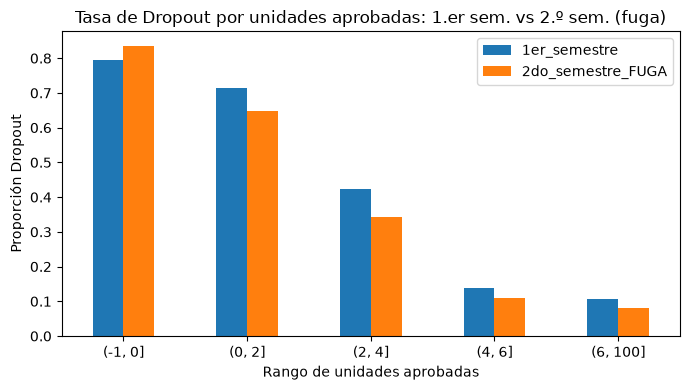

In [11]:
t = pd.DataFrame(res["tasa_dropout_por_unidades_aprobadas"])
display(t)
ax = t.plot.bar(figsize=(7, 4))
ax.set_title("Tasa de Dropout por unidades aprobadas: 1.er sem. vs 2.º sem. (fuga)")
ax.set_xlabel("Rango de unidades aprobadas"); ax.set_ylabel("Proporción Dropout"); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(FIG / "03_fuga_segundo_semestre.png", dpi=150); plt.show()

In [12]:
df_u = eliminar_duplicados(df)          # duplicados ANTES de particionar
train, val, prueba = particionar(df_u)
verificar_sin_fuga(train, val, prueba)  # lanza ValueError si hay solape
rp = resumen_particion(train, val, prueba)
print({k: rp[k] for k in ["filas_train", "filas_val", "filas_test", "semilla"]})
display(pd.DataFrame(rp["proporcion_clases"]))

{'filas_train': 3096, 'filas_val': 664, 'filas_test': 664, 'semilla': 42}


,train,val,prueba
Graduate,0.4990,0.5000,0.5000
Dropout,0.3214,0.3208,0.3208
Enrolled,0.1796,0.1792,0.1792


In [13]:
X_train, _ = separar_xy(train)
X_val, _ = separar_xy(val)
esc = StandardScaler().fit(X_train)     # fit SOLO con entrenamiento
Xv = esc.transform(X_val)               # validación solo se transforma
print("Media (train) usada para escalar:", dict(zip(X_train.columns, esc.mean_.round(3))))
print("Media de validación sin escalar: ", X_val.mean().round(3).to_dict())

Media (train) usada para escalar: {'Curricular units 1st sem (enrolled)': np.float64(6.272), 'Curricular units 1st sem (approved)': np.float64(4.713), 'Curricular units 1st sem (grade)': np.float64(10.64), 'Tuition fees up to date': np.float64(0.881), 'Debtor': np.float64(0.109), 'Scholarship holder': np.float64(0.251), 'Age at enrollment': np.float64(23.309), 'Admission grade': np.float64(127.0)}
Media de validación sin escalar:  {'Curricular units 1st sem (enrolled)': 6.233, 'Curricular units 1st sem (approved)': 4.681, 'Curricular units 1st sem (grade)': 10.496, 'Tuition fees up to date': 0.881, 'Debtor': 0.117, 'Scholarship holder': 0.248, 'Age at enrollment': 23.173, 'Admission grade': 126.67}
